# 03. One-stage anchor-based detector: RetinaNet
RetinaNet ResNet50-FPN v2 (torchvision, COCO-pretrained): dense anchors on P3–P7 (9 per location),
focal loss for classification, GIoU loss for boxes, GroupNorm in the heads.
Same protocol as Faster R-CNN (`tv_utils.py`), except lr = 0.0025 for batch 2: torchvision reference
scripts use half the Faster R-CNN learning rate for RetinaNet (0.01 vs 0.02 at batch 16).

In [ ]:
import os; os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
%load_ext autoreload
%autoreload 2
import sys, json, pickle, subprocess
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())))

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from common import (PROC, ROOT, PROJECT, CLASSES, CHECKPOINTS, seed_everything, write_submission, load_results,
                    coco_evaluate, error_analysis, best_f1_threshold)
import tv_utils as tv

seed_everything()
DEVICE = "cuda"
VAL_GT = PROC / "val_gt.json"
train_ds = tv.YoloDetDataset("s10", "train", train=True)
test_df = pd.read_csv(ROOT / "test_images.csv")
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
RET_BASE_CFG = dict(model="retinanet_r50_fpn_v2", anchors="32-512", fg_bg_iou="0.5/0.4", focal_alpha=0.25,
                    focal_gamma=2.0, box_loss="giou", epochs=12, batch_size=2, lr=0.0025,
                    long_side=tv.LONG_SIDE, train_frames=len(train_ds))

## 1. Do the default anchors fit our objects?
A one-stage detector has no proposal stage: every anchor is directly classified, and an object is learned
only through the anchors assigned to it (IoU >= 0.5 with the default matcher). We check, without training,
how many anchors and positives an image gets and how well the best anchor fits each object, for the default
anchors (32–512) and for anchors halved to match the k-means sizes from 01_data (12–113 px at 1280).

In [5]:
rows = {}
for name, base in [("default 32-512", (32, 64, 128, 256, 512)), ("halved 16-256", (16, 32, 64, 128, 256))]:
    m = tv.build_retinanet(anchor_base=base)
    summary, by_size = tv.anchor_coverage(m, train_ds, n_images=100, device=DEVICE)
    print(name, summary); display(by_size)
    del m; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /home/julia/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:13<00:00, 11.4MB/s] 


default 32-512 {'anchors / image': 176580, 'positive anchors / image': 603.5, 'neg : pos ratio': 291}


,best anchor IoU >= 0.5,best anchor IoU
size,,
small,0.490,0.478
medium,0.999,0.766
large,1.000,0.786


halved 16-256 {'anchors / image': 176580, 'positive anchors / image': 287.4, 'neg : pos ratio': 613}


,best anchor IoU >= 0.5,best anchor IoU
size,,
small,0.924,0.651
medium,0.993,0.671
large,1.000,0.687


## 2. Baseline
Default anchors (base sizes 32–512, 3 scales x 3 ratios), positives at IoU >= 0.5, negatives < 0.4,
focal loss alpha = 0.25, gamma = 2.

In [6]:
seed_everything()
tv.set_focal_loss(alpha=0.25, gamma=2.0)
model = tv.build_retinanet()
hist = tv.train_detector(model, "retina_base", train_ds, VAL_GT, epochs=12, batch_size=2, lr=0.0025, warmup_iters=600)
hist.to_csv(PROJECT / "results" / "retina_base_history.csv", index=False)
res_base, _ = tv.evaluate_run(model, "retina_base", VAL_GT, RET_BASE_CFG)
display(pd.Series(res_base).to_frame().T)

{'epoch': 1, 'train_min': 5.1, 'classification': 0.3904, 'bbox_regression': 0.2618, 'mAP': 0.1461, 'AP50': 0.2748, 'AP_small': 0.0501}
{'epoch': 2, 'train_min': 4.8, 'classification': 0.2463, 'bbox_regression': 0.2428, 'mAP': 0.1759, 'AP50': 0.335, 'AP_small': 0.0556}
{'epoch': 3, 'train_min': 4.8, 'classification': 0.2145, 'bbox_regression': 0.2353, 'mAP': 0.1853, 'AP50': 0.3388, 'AP_small': 0.0594}
{'epoch': 4, 'train_min': 4.5, 'classification': 0.1916, 'bbox_regression': 0.2303, 'mAP': 0.1753, 'AP50': 0.3321, 'AP_small': 0.0593}
{'epoch': 5, 'train_min': 4.8, 'classification': 0.1774, 'bbox_regression': 0.226, 'mAP': 0.1921, 'AP50': 0.3601, 'AP_small': 0.0505}
{'epoch': 6, 'train_min': 4.8, 'classification': 0.1653, 'bbox_regression': 0.2228, 'mAP': 0.1935, 'AP50': 0.3626, 'AP_small': 0.0628}
{'epoch': 7, 'train_min': 4.2, 'classification': 0.1542, 'bbox_regression': 0.2196, 'mAP': 0.1969, 'AP50': 0.375, 'AP_small': 0.0639}
{'epoch': 8, 'train_min': 4.1, 'classification': 0.1464, '

,name,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AP_person,AP_bicycle,AP_car,...,anchors,fg_bg_iou,focal_alpha,focal_gamma,box_loss,epochs,batch_size,lr,long_side,train_frames
0,retina_base,0.2065,0.3845,0.195,0.0716,0.1769,0.3858,0.24,0.1566,0.4607,...,32-512,0.5/0.4,0.25,2.0,giou,12,2,0.0025,1280,2446


## 3. Experiment 1: anchors matched to the object sizes
Base anchor sizes halved to (16, 32, 64, 128, 256): the smallest anchor (16 px at stride 8) now fits the
12–30 px objects. 9 anchors per location as before, so the pretrained regression head is kept.

In [7]:
del model; torch.cuda.empty_cache(); seed_everything()
tv.set_focal_loss(alpha=0.25, gamma=2.0)
RET_ANCH_CFG = {**RET_BASE_CFG, "anchors": "16-256"}
model = tv.build_retinanet(anchor_base=(16, 32, 64, 128, 256))
hist = tv.train_detector(model, "retina_anchors", train_ds, VAL_GT, epochs=12, batch_size=2, lr=0.0025, warmup_iters=600)
hist.to_csv(PROJECT / "results" / "retina_anchors_history.csv", index=False)
res_anch, _ = tv.evaluate_run(model, "retina_anchors", VAL_GT, RET_ANCH_CFG)
res_base = json.load(open(PROJECT / "results" / "retina_base.json"))
display(pd.DataFrame([res_base, res_anch]).set_index("name")[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]])

{'epoch': 1, 'train_min': 4.1, 'classification': 0.4543, 'bbox_regression': 0.3687, 'mAP': 0.1156, 'AP50': 0.2573, 'AP_small': 0.0569}
{'epoch': 2, 'train_min': 4.1, 'classification': 0.2931, 'bbox_regression': 0.2802, 'mAP': 0.149, 'AP50': 0.3201, 'AP_small': 0.056}
{'epoch': 3, 'train_min': 4.1, 'classification': 0.2579, 'bbox_regression': 0.2679, 'mAP': 0.1707, 'AP50': 0.3611, 'AP_small': 0.0665}
{'epoch': 4, 'train_min': 4.1, 'classification': 0.2349, 'bbox_regression': 0.2604, 'mAP': 0.1727, 'AP50': 0.3696, 'AP_small': 0.0646}
{'epoch': 5, 'train_min': 4.1, 'classification': 0.2185, 'bbox_regression': 0.255, 'mAP': 0.1742, 'AP50': 0.3676, 'AP_small': 0.0611}
{'epoch': 6, 'train_min': 4.1, 'classification': 0.2048, 'bbox_regression': 0.2505, 'mAP': 0.182, 'AP50': 0.3797, 'AP_small': 0.0714}
{'epoch': 7, 'train_min': 4.1, 'classification': 0.1925, 'bbox_regression': 0.2463, 'mAP': 0.176, 'AP50': 0.3798, 'AP_small': 0.0705}
{'epoch': 8, 'train_min': 4.1, 'classification': 0.1827, 'bb

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
name,,,,,,
retina_base,0.2065,0.3845,0.1950,0.0716,0.1769,0.3858
retina_anchors,0.1871,0.3931,0.1559,0.0744,0.1737,0.3269


## 4. Experiment 2: focal loss gamma
Gamma controls how strongly easy negatives are down-weighted. With ~100k anchors per image and dense scenes,
many anchors near small objects are "hard" but ambiguous; a lower gamma (1.5) gives more weight to moderately
easy examples and makes the loss less dominated by a few hard ones. Applied on top of the better anchor setting.

In [8]:
best_anch = (16, 32, 64, 128, 256) if res_anch["mAP"] > res_base["mAP"] else (32, 64, 128, 256, 512)
del model; torch.cuda.empty_cache(); seed_everything()
tv.set_focal_loss(alpha=0.25, gamma=1.5)
RET_FOCAL_CFG = {**(RET_ANCH_CFG if best_anch[0] == 16 else RET_BASE_CFG), "focal_gamma": 1.5}
model = tv.build_retinanet(anchor_base=best_anch)
hist = tv.train_detector(model, "retina_focal", train_ds, VAL_GT, epochs=12, batch_size=2, lr=0.0025, warmup_iters=600)
hist.to_csv(PROJECT / "results" / "retina_focal_history.csv", index=False)
res_focal, _ = tv.evaluate_run(model, "retina_focal", VAL_GT, RET_FOCAL_CFG)
tv.set_focal_loss(alpha=0.25, gamma=2.0)   # restore the default

{'epoch': 1, 'train_min': 4.1, 'classification': 0.4881, 'bbox_regression': 0.2614, 'mAP': 0.1587, 'AP50': 0.297, 'AP_small': 0.0518}
{'epoch': 2, 'train_min': 4.1, 'classification': 0.3166, 'bbox_regression': 0.2423, 'mAP': 0.1819, 'AP50': 0.3439, 'AP_small': 0.0554}
{'epoch': 3, 'train_min': 4.1, 'classification': 0.276, 'bbox_regression': 0.2347, 'mAP': 0.187, 'AP50': 0.3435, 'AP_small': 0.0549}
{'epoch': 4, 'train_min': 4.1, 'classification': 0.2473, 'bbox_regression': 0.2296, 'mAP': 0.1797, 'AP50': 0.3372, 'AP_small': 0.0558}
{'epoch': 5, 'train_min': 4.1, 'classification': 0.228, 'bbox_regression': 0.2252, 'mAP': 0.195, 'AP50': 0.3638, 'AP_small': 0.0503}
{'epoch': 6, 'train_min': 4.1, 'classification': 0.2123, 'bbox_regression': 0.2219, 'mAP': 0.1951, 'AP50': 0.3663, 'AP_small': 0.062}
{'epoch': 7, 'train_min': 4.1, 'classification': 0.1981, 'bbox_regression': 0.2186, 'mAP': 0.1977, 'AP50': 0.3775, 'AP_small': 0.0624}
{'epoch': 8, 'train_min': 4.1, 'classification': 0.1876, 'bbo

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image
name,,,,,,,
frcnn_giou,0.2493,0.4995,0.2207,0.1037,0.2349,0.4058,44.1
retina_base,0.2065,0.3845,0.1950,0.0716,0.1769,0.3858,28.7
retina_anchors,0.1871,0.3931,0.1559,0.0744,0.1737,0.3269,28.6
retina_focal,0.2108,0.3969,0.2007,0.0613,0.1826,0.3946,28.6


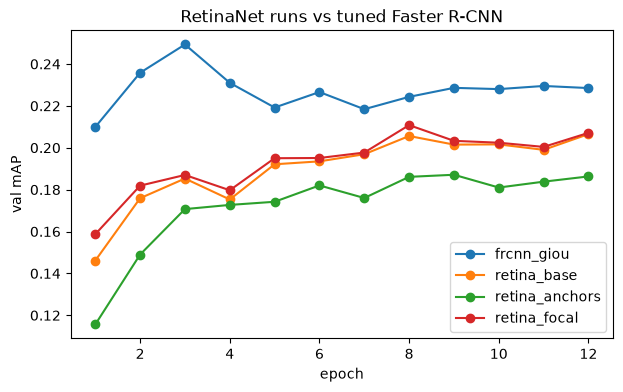

In [9]:
cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms_per_image"]
names = ["frcnn_giou", "retina_base", "retina_anchors", "retina_focal"]
display(load_results().set_index("name").loc[names, cols])
fig, ax = plt.subplots(figsize=(7, 4))
for n in names:
    h = pd.read_csv(PROJECT / "results" / f"{n}_history.csv"); ax.plot(h.epoch, h.mAP, marker="o", label=n)
ax.set_xlabel("epoch"); ax.set_ylabel("val mAP"); ax.legend(); ax.set_title("RetinaNet runs vs tuned Faster R-CNN")
plt.show()